# Empirical Asset Pricing in Indian Equities: Factor Premia, Pricing Errors and Regime Dependence
### Testing CAPM, Fama–French Three-Factor and Carhart Four-Factor Models (1993–2025)

**Author:** Quantitative Finance Research Group  
**Dataset:** IIM Ahmedabad Fama-French & Momentum Factors Library (CMIE Prowess DX + RBI)  
**Sample Period:** November 1993 to December 2025 ($T = 386$ monthly observations / 8,004 daily observations)

---
## Theoretical Overview & Asset Pricing Foundations

### 1. Stochastic Discount Factor (SDF) Representation
Under no-arbitrage, the price of any asset satisfies the Euler equation:
$$P_t = \mathbb{E}_t [m_{t+1} X_{t+1}]$$
For gross returns $R_{i,t+1} = X_{i,t+1}/P_{i,t}$, we have $\mathbb{E}_t [m_{t+1} R_{i,t+1}] = 1$. Since $R_f = 1/\mathbb{E}_t[m_{t+1}]$, expected excess returns satisfy the fundamental covariance pricing equation:
$$\mathbb{E}_t[R_{i,t+1}] - R_f = - R_f 	ext{Cov}_t(m_{t+1}, R_{i,t+1}) = eta_{i,m} \lambda_m$$

### 2. Factor Model Specifications
1. **Capital Asset Pricing Model (CAPM):**
   $$R_{it} - R_{ft} = lpha_i + eta_{iM} (R_{mt} - R_{ft}) + \epsilon_{it}$$
2. **Fama–French Three-Factor Model (FF3):**
   $$R_{it} - R_{ft} = lpha_i + eta_{iM} MF_t + eta_{iS} SMB_t + eta_{iH} HML_t + \epsilon_{it}$$
3. **Carhart Four-Factor Model (FF4):**
   $$R_{it} - R_{ft} = lpha_i + eta_{iM} MF_t + eta_{iS} SMB_t + eta_{iH} HML_t + eta_{iW} WML_t + \epsilon_{it}$$


In [1]:
# Setup environment and imports
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
notebook_dir = Path.cwd()
project_root = notebook_dir.parent if notebook_dir.name == "notebooks" else notebook_dir
sys.path.append(str(project_root))

from config import config
from src.data_loader import load_master_dataset
from src.cleaning import generate_data_quality_report, generate_subsample_breakdown
from src.factors import compute_factor_descriptive_stats, compute_factor_correlations, compute_rolling_factor_stats
from src.portfolios import get_test_portfolio_excess_returns, compute_portfolio_summary_stats
from src.regressions import build_regression_table, generate_and_save_all_regression_tables
from src.evaluation import compare_all_models_pricing_errors
from src.grs import compute_grs_test, run_grs_suite
from src.regimes import fit_market_regime_hmm, analyze_factors_across_regimes
from src.backtest import run_factor_backtests, run_transaction_cost_sensitivity
from src.robustness import run_subsample_robustness_analysis, run_hac_lag_sensitivity

# Set plotting aesthetics
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['figure.dpi'] = 120
print("Environment configured successfully. Ready for empirical analysis.")


Environment configured successfully. Ready for empirical analysis.


---
## Section 1: Data Ingestion & Quality Audit (Steps 0.1–0.12)
We load the synchronized monthly master panel covering **November 1993 to December 2025** ($T=386$ months).


In [2]:
master_df = load_master_dataset()
print(f"Master Dataset Dimensions: {master_df.shape} (Months x Variables)")
print(f"Sample Date Range: {master_df.index[0]} to {master_df.index[-1]}")
master_df.head()


Master Dataset Dimensions: (386, 15) (Months x Variables)
Sample Date Range: 1993-11 to 2025-12


,SMB,HML,WML,MF,RF,BV,BN,BG,SV,SN,SG,WB,WS,LB,LS
Date,,,,,,,,,,,,,,,
1993-11,-9.422705,-0.558587,12.621234,17.621894,0.611432,21.329213,19.390862,20.944761,9.182351,8.538545,10.960601,21.175479,11.418063,2.923695,3.331110
1993-12,-3.774003,7.553438,-3.304450,8.292192,0.613010,21.638673,9.649439,8.596474,10.833536,9.752577,7.756268,5.779866,9.886938,11.670043,9.647286
1994-01,5.300461,-4.186320,-5.098960,18.717821,0.856797,12.211925,23.246007,16.384560,21.777457,21.036218,28.180012,19.970889,20.204033,22.132021,26.912362
1994-02,3.639386,-2.572361,5.061961,4.886871,0.620017,3.489561,2.264407,6.124381,6.188791,9.547731,8.753343,6.188922,9.099233,NaN,3.845194
1994-03,2.314400,-1.897144,-0.998293,-13.212380,0.618383,-12.109523,-20.685436,-9.753887,-12.543626,-12.172243,-11.346582,-11.868135,-11.653034,-8.571612,-13.270940


In [3]:
# Data quality and missingness audit
quality_rep = generate_data_quality_report()
quality_rep


,Variable,Category,Total Months,Valid Months,Missing Months,Missingness (%),First Valid Month,Last Valid Month
0,SMB,Factor / Benchmark,386,385,1,0.26,1993-11,2025-12
1,HML,Factor / Benchmark,386,385,1,0.26,1993-11,2025-12
2,WML,Factor / Benchmark,386,385,1,0.26,1993-11,2025-12
3,MF,Factor / Benchmark,386,386,0,0.00,1993-11,2025-12
4,RF,Factor / Benchmark,386,386,0,0.00,1993-11,2025-12
5,BV,Size-Value Test Portfolio,386,232,154,39.90,1993-11,2025-12
6,BN,Size-Value Test Portfolio,386,386,0,0.00,1993-11,2025-12
7,BG,Size-Value Test Portfolio,386,386,0,0.00,1993-11,2025-12
8,SV,Size-Value Test Portfolio,386,385,1,0.26,1993-11,2025-12
9,SN,Size-Value Test Portfolio,386,385,1,0.26,1993-11,2025-12


---
## Section 2: Factor Descriptive Statistics & Correlation Structure
We compute annualized means, standard deviations, Sharpe ratios, skewness, kurtosis, autocorrelations, and $t$-tests for each factor.


In [4]:
factor_stats = compute_factor_descriptive_stats(master_df)
factor_stats


,Factor,N,Monthly Mean (%),Monthly Std (%),Annualized Mean (%),Annualized Std (%),Annualized Sharpe,t-stat (Mean),p-value,Skewness,Excess Kurtosis,Min (%),Max (%),Autocorr Lag 1,Autocorr Lag 12
0,MF,386,0.72,7.09,8.61,24.56,0.35,1.99,0.0476,-0.25,2.14,-29.06,33.55,0.12,-0.04
1,SMB,385,-0.24,4.83,-2.92,16.72,-0.17,-0.99,0.3236,0.05,0.35,-14.09,14.28,0.13,0.08
2,HML,385,0.71,5.87,8.50,20.35,0.42,2.37,0.0185,0.60,1.88,-18.97,24.64,0.06,-0.05
3,WML,385,1.11,7.08,13.35,24.51,0.54,3.08,0.0022,0.05,3.61,-27.61,35.82,0.17,0.06
4,RF,386,0.56,0.16,6.71,0.57,11.77,66.73,0.0000,0.49,0.58,0.23,1.11,0.93,0.58


In [5]:
# Factor Correlation Matrices
corrs = compute_factor_correlations(master_df)
print("=== Full Sample Factor Correlation Matrix (1993-2025) ===")
display(corrs['full'].round(3))


=== Full Sample Factor Correlation Matrix (1993-2025) ===


,MF,SMB,HML,WML
MF,1.000,0.246,0.219,-0.145
SMB,0.246,1.000,0.154,-0.188
HML,0.219,0.154,1.000,-0.368
WML,-0.145,-0.188,-0.368,1.000


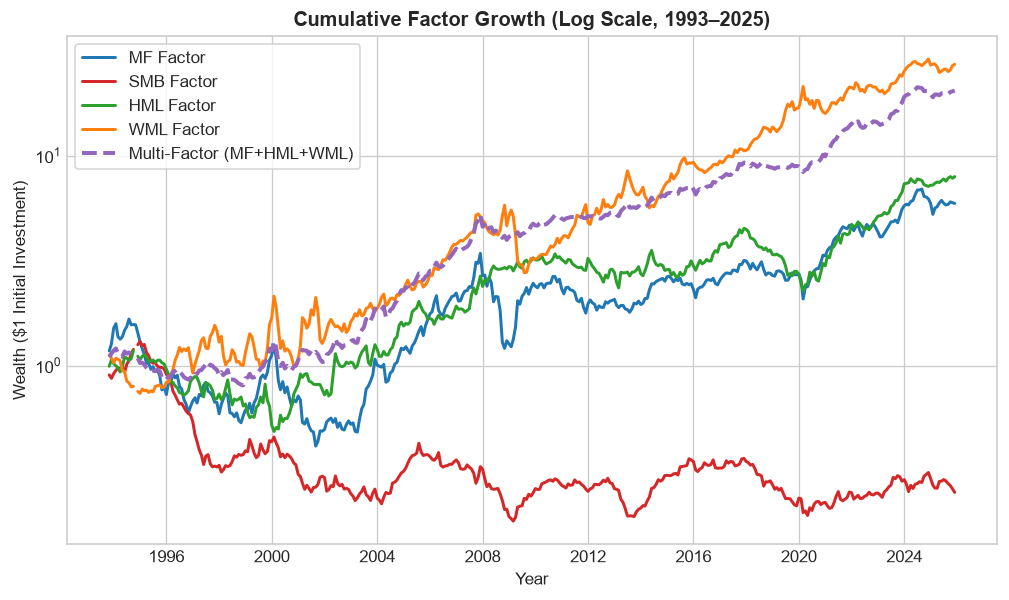

In [6]:
# Visualize Cumulative Factor Returns
dates = master_df.index.to_timestamp()
plt.figure(figsize=(10, 5.5))
for f, col in [('MF', '#1f77b4'), ('SMB', '#d62728'), ('HML', '#2ca02c'), ('WML', '#ff7f0e')]:
    w = (1.0 + master_df[f]/100.0).cumprod()
    plt.plot(dates, w, label=f"{f} Factor", color=col, lw=1.8)

mf_3f = (master_df['MF'] + master_df['HML'] + master_df['WML']) / (3.0 * 100.0)
plt.plot(dates, (1.0 + mf_3f).cumprod(), label="Multi-Factor (MF+HML+WML)", color='#9467bd', lw=2.4, ls='--')

plt.yscale('log')
plt.title("Cumulative Factor Growth (Log Scale, 1993–2025)", fontweight='bold')
plt.xlabel("Year")
plt.ylabel("Wealth ($1 Initial Investment)")
plt.legend(frameon=True)
plt.show()


---
## Section 3: Time-Series Asset Pricing Regressions (CAPM, FF3, Carhart FF4)
All regressions are estimated via OLS with **Newey-West (1987) HAC robust standard errors** ($L=3$ lags).


In [7]:
# 1. CAPM Regressions
capm_table = build_regression_table(model_name="CAPM", df=master_df)
print("=== CAPM Time-Series Regression Results (Full Sample) ===")
display(capm_table)


=== CAPM Time-Series Regression Results (Full Sample) ===


,Portfolio,N,Alpha (%/mo),t(Alpha),p(Alpha),Beta_MF,t(MF),p(MF),R2 (%),Adj-R2 (%),DW Stat,LB p-val,Resid Vol (%)
0,SV,385,0.38,1.07,0.286,1.33,23.46,0.0,64.4,64.3,1.85,0.359,7.05
1,SN,385,0.17,0.64,0.521,1.18,22.98,0.0,73.2,73.1,1.78,0.207,5.08
2,SG,386,-0.14,-0.63,0.528,1.12,29.83,0.0,79.0,78.9,1.84,0.458,4.09
3,BV,232,0.79,1.56,0.118,1.06,9.64,0.0,42.6,42.3,2.10,0.414,8.34
4,BN,386,0.36,1.49,0.136,1.06,21.01,0.0,75.0,74.9,1.74,0.004,4.36
5,BG,386,-0.05,-0.65,0.515,0.96,71.51,0.0,96.7,96.7,1.53,0.000,1.27
6,WS,386,0.44,1.73,0.084,1.16,27.89,0.0,75.8,75.7,1.75,0.135,4.64
7,WB,384,0.56,2.92,0.003,1.02,20.64,0.0,80.3,80.2,1.80,0.129,3.58
8,LS,385,-0.54,-1.46,0.144,1.33,13.73,0.0,63.3,63.2,1.76,0.051,7.20
9,LB,380,-0.45,-1.28,0.202,1.16,12.19,0.0,60.4,60.3,1.75,0.028,6.67


In [8]:
# 2. Fama-French 3-Factor Regressions
ff3_table = build_regression_table(model_name="FF3", df=master_df)
print("=== Fama-French 3-Factor Regression Results (Full Sample) ===")
display(ff3_table)


=== Fama-French 3-Factor Regression Results (Full Sample) ===


,Portfolio,N,Alpha (%/mo),t(Alpha),p(Alpha),Beta_MF,t(MF),p(MF),Beta_SMB,t(SMB),p(SMB),Beta_HML,t(HML),p(HML),R2 (%),Adj-R2 (%),DW Stat,LB p-val,Resid Vol (%)
0,SV,385,0.23,2.54,0.011,1.03,63.89,0.0,0.93,34.83,0.000,0.84,46.73,0.000,97.9,97.9,1.87,0.637,1.72
1,SN,385,0.20,1.66,0.097,0.97,32.84,0.0,0.76,23.37,0.000,0.44,12.63,0.000,95.1,95.1,1.88,0.641,2.18
2,SG,385,0.02,0.18,0.861,0.98,39.31,0.0,0.68,19.80,0.000,0.12,2.93,0.003,93.1,93.1,1.87,0.502,2.34
3,BV,232,-0.27,-1.40,0.160,0.91,26.59,0.0,-0.43,-7.44,0.000,1.31,24.04,0.000,93.7,93.6,1.91,0.374,2.78
4,BN,385,0.06,0.33,0.744,1.05,26.39,0.0,-0.29,-5.28,0.000,0.35,7.70,0.000,81.9,81.7,1.97,0.641,3.72
5,BG,385,0.01,0.10,0.924,1.00,96.05,0.0,-0.07,-5.21,0.000,-0.13,-10.26,0.000,98.2,98.2,1.70,0.003,0.93
6,WS,385,0.55,3.48,0.001,1.00,27.52,0.0,0.72,19.43,0.000,0.22,6.59,0.000,91.8,91.7,1.58,0.000,2.71
7,WB,383,0.60,3.12,0.002,1.06,22.65,0.0,-0.11,-1.90,0.058,-0.16,-3.48,0.001,82.0,81.9,1.82,0.120,3.43
8,LS,385,-0.55,-2.21,0.027,1.07,14.76,0.0,0.89,12.76,0.000,0.58,9.84,0.000,85.5,85.4,1.69,0.026,4.53
9,LB,379,-0.59,-1.76,0.079,1.08,12.01,0.0,0.14,1.42,0.156,0.31,3.99,0.000,63.9,63.6,1.78,0.146,6.39


In [9]:
# 3. Carhart 4-Factor Regressions (with Momentum)
ff4_table = build_regression_table(model_name="FF4", df=master_df)
print("=== Carhart 4-Factor Regression Results (Full Sample) ===")
display(ff4_table)


=== Carhart 4-Factor Regression Results (Full Sample) ===


,Portfolio,N,Alpha (%/mo),t(Alpha),p(Alpha),Beta_MF,t(MF),p(MF),Beta_SMB,t(SMB),...,t(HML),p(HML),Beta_WML,t(WML),p(WML),R2 (%),Adj-R2 (%),DW Stat,LB p-val,Resid Vol (%)
0,SV,385,0.26,2.95,0.003,1.02,64.53,0.0,0.93,35.85,...,42.71,0.000,-0.02,-1.16,0.246,97.9,97.9,1.85,0.562,1.72
1,SN,385,0.34,3.29,0.001,0.97,38.69,0.0,0.74,24.83,...,13.40,0.000,-0.10,-2.84,0.005,95.6,95.5,1.80,0.196,2.08
2,SG,385,0.14,1.22,0.221,0.98,45.27,0.0,0.67,20.14,...,2.49,0.013,-0.08,-3.37,0.001,93.5,93.4,1.84,0.368,2.28
3,BV,232,-0.26,-1.38,0.167,0.91,27.02,0.0,-0.43,-7.60,...,20.63,0.000,-0.01,-0.27,0.788,93.7,93.6,1.91,0.359,2.78
4,BN,385,0.26,1.68,0.093,1.04,27.24,0.0,-0.32,-5.96,...,7.78,0.000,-0.14,-2.23,0.026,83.0,82.8,1.86,0.345,3.61
5,BG,385,-0.02,-0.48,0.629,1.00,97.02,0.0,-0.06,-4.63,...,-11.57,0.000,0.02,1.34,0.180,98.2,98.2,1.66,0.001,0.92
6,WS,385,0.21,1.86,0.063,1.01,49.69,0.0,0.77,28.03,...,9.81,0.000,0.24,10.23,0.000,94.6,94.6,1.80,0.132,2.19
7,WB,383,0.09,0.69,0.492,1.08,50.88,0.0,-0.03,-0.97,...,-0.03,0.972,0.38,12.34,0.000,91.5,91.4,1.83,0.184,2.36
8,LS,385,0.20,1.19,0.233,1.05,31.90,0.0,0.79,20.99,...,11.95,0.000,-0.55,-12.37,0.000,94.5,94.4,1.71,0.044,2.80
9,LB,379,0.62,3.39,0.001,1.05,30.97,0.0,-0.03,-0.82,...,-1.09,0.278,-0.86,-20.16,0.000,91.9,91.8,1.81,0.368,3.03


---
## Section 4: Pricing Error Analysis & Cross-Model Comparison
We compare Mean Absolute Alpha ($MAA$), RMS Alpha, Max $|lpha|$, and Mean $R^2$ across models.


In [10]:
pricing_errors = compare_all_models_pricing_errors(sample_name="full_sample")
print("=== Full Sample Pricing Error Comparison (CAPM vs FF3 vs FF4) ===")
display(pricing_errors)


=== Full Sample Pricing Error Comparison (CAPM vs FF3 vs FF4) ===


,Model,N_Portfolios,MAA (%/mo),MAA Annualized (%),RMS Alpha (%/mo),RMS Alpha Annualized (%),Max |Alpha| (%/mo),Max |Alpha| Annualized (%),Sig Alphas (p<0.05),Sig Alphas (p<0.10),Mean R2 (%),Mean Adj-R2 (%),Mean Resid Vol (%/mo)
0,CAPM,9,0.343,4.12,0.384,4.61,0.56,6.72,1/9,2/9,74.2,74.1,4.88
1,FF3,9,0.312,3.75,0.396,4.75,0.60,7.20,4/9,6/9,87.7,87.6,3.11
2,FF4,9,0.238,2.85,0.288,3.46,0.62,7.44,3/9,5/9,93.4,93.3,2.33


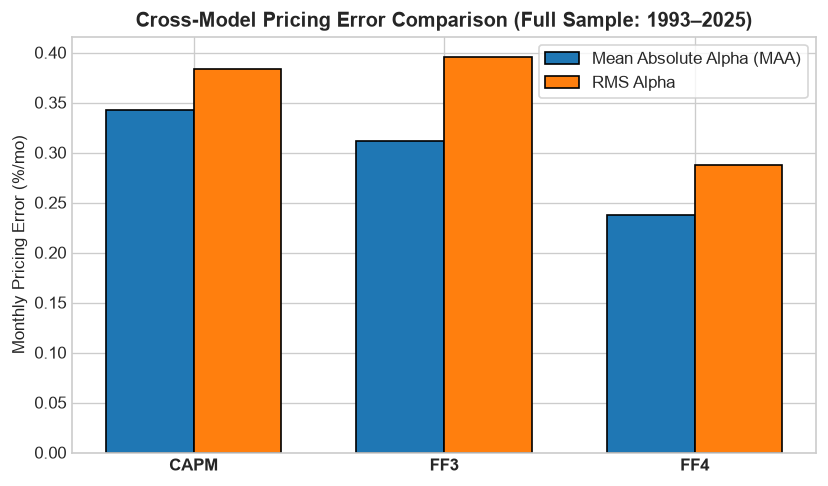

In [11]:
# Plot Pricing Error Comparison
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(pricing_errors))
width = 0.35
ax.bar(x - width/2, pricing_errors['MAA (%/mo)'], width, label='Mean Absolute Alpha (MAA)', color='#1f77b4', edgecolor='black')
ax.bar(x + width/2, pricing_errors['RMS Alpha (%/mo)'], width, label='RMS Alpha', color='#ff7f0e', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(pricing_errors['Model'], fontweight='bold')
ax.set_ylabel("Monthly Pricing Error (%/mo)")
ax.set_title("Cross-Model Pricing Error Comparison (Full Sample: 1993–2025)", fontweight='bold')
ax.legend(frameon=True)
plt.show()


---
## Section 5: Gibbons–Ross–Shanken (GRS) Exact Joint Hypothesis Test
$$H_0: oldsymbol{lpha} = [lpha_1, lpha_2, \dots, lpha_N]' = \mathbf{0}$$
$$GRS = rac{T - N - K}{N} \left( 1 + \hat{oldsymbol{\mu}}_F' \hat{oldsymbol{\Sigma}}_F^{-1} \hat{oldsymbol{\mu}}_F ight)^{-1} \hat{oldsymbol{lpha}}' \hat{oldsymbol{\Sigma}}_\epsilon^{-1} \hat{oldsymbol{lpha}} \sim F_{N, T - N - K}$$


In [12]:
grs_results = run_grs_suite(master_df)
display(grs_results)


,Sample Period,Test Asset Set,Model,N,K,T,GRS Stat,"df1, df2",p-value,Reject H0 (5%),MAA (%/mo),RMS Alpha (%/mo)
0,Full Sample (1993-2025),9 Balanced Portfolios,CAPM,9,1,377,3.049,"(9, 367)",0.0016,Yes,0.336,0.376
1,Full Sample (1993-2025),9 Balanced Portfolios,FF3,9,3,377,5.382,"(9, 365)",0.0000,Yes,0.306,0.388
2,Full Sample (1993-2025),9 Balanced Portfolios,FF4,9,4,377,4.291,"(9, 364)",0.0000,Yes,0.234,0.286
3,Full Sample (1993-2025),5 Size-Value Portfolios,CAPM,5,1,385,1.658,"(5, 379)",0.1440,No,0.225,0.260
4,Full Sample (1993-2025),5 Size-Value Portfolios,FF3,5,3,385,5.021,"(5, 377)",0.0002,Yes,0.104,0.139
5,Full Sample (1993-2025),5 Size-Value Portfolios,FF4,5,4,385,5.542,"(5, 376)",0.0001,Yes,0.203,0.231
6,Full Sample (1993-2025),4 Size-Momentum Portfolios,CAPM,4,1,377,3.456,"(4, 372)",0.0087,Yes,0.487,0.491
7,Full Sample (1993-2025),4 Size-Momentum Portfolios,FF3,4,3,377,4.731,"(4, 370)",0.0010,Yes,0.562,0.562
8,Full Sample (1993-2025),4 Size-Momentum Portfolios,FF4,4,4,377,6.051,"(4, 369)",0.0001,Yes,0.275,0.343
9,In-Sample (1993-2015),9 Balanced Portfolios,CAPM,9,1,257,1.864,"(9, 247)",0.0579,No,0.315,0.374


---
## Section 6: Market Regime Analysis (2-State Gaussian Hidden Markov Model)
We classify market conditions into **State 0 (Normal / Low-Volatility)** and **State 1 (Crisis / High-Volatility)**.


In [13]:
regime_dict = fit_market_regime_hmm(master_df)
print("=== HMM Regime Parameters & Transition Persistence ===")
display(regime_dict['char_table'])


=== HMM Regime Parameters & Transition Persistence ===


,Regime,Monthly Mean MF (%),Annualized Mean MF (%),Monthly Std MF (%),Annualized Std MF (%),Stay Probability (P_ii),Expected Duration (Months),Months in Regime,Proportion of Sample (%)
0,Low-Volatility (Normal),0.63,7.62,4.28,14.81,0.993,134.6,190,49.2
1,High-Volatility (Crisis),0.80,9.56,9.00,31.16,0.988,82.0,196,50.8


In [14]:
factor_regimes = analyze_factors_across_regimes(regime_dict)
print("=== Factor Risk Premia Conditional on Market Regimes ===")
display(factor_regimes)


=== Factor Risk Premia Conditional on Market Regimes ===


,Factor,Normal Mean (%/mo),Normal Ann Mean (%),Normal Ann Vol (%),Normal Sharpe,Crisis Mean (%/mo),Crisis Ann Mean (%),Crisis Ann Vol (%),Crisis Sharpe,Diff (Norm - Cris),t-stat (Diff),p-value (Diff)
0,MF,0.66,7.86,14.71,0.53,0.78,9.33,31.33,0.30,-1.47,-0.17,0.8644
1,SMB,0.17,2.05,13.48,0.15,-0.65,-7.76,19.30,-0.40,9.81,1.67,0.0954
2,HML,0.66,7.89,16.30,0.48,0.76,9.10,23.67,0.38,-1.21,-0.17,0.8663
3,WML,1.18,14.19,15.68,0.90,1.04,12.53,30.82,0.41,1.66,0.19,0.8474


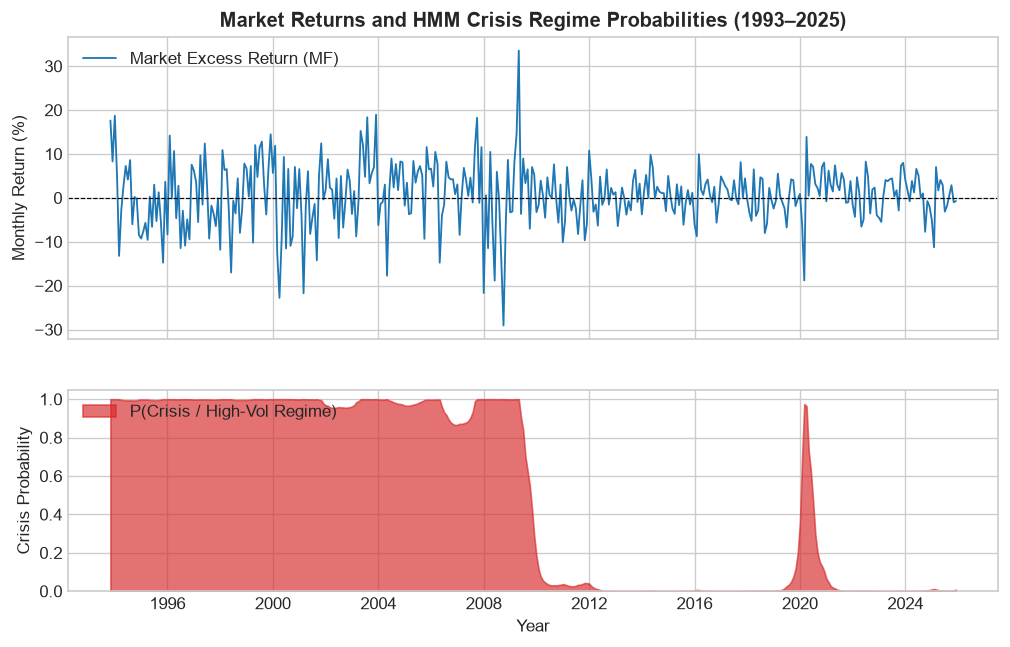

In [15]:
# Plot Regime Probabilities
reg_df = regime_dict['regime_df']
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={'height_ratios': [1.5, 1]})
ax1.plot(dates, reg_df['MF'], color='#1f77b4', lw=1.1, label='Market Excess Return (MF)')
ax1.axhline(0, color='black', ls='--', lw=0.7)
ax1.set_ylabel("Monthly Return (%)")
ax1.set_title("Market Returns and HMM Crisis Regime Probabilities (1993–2025)", fontweight='bold')
ax1.legend(loc='upper left')

ax2.fill_between(dates, 0, reg_df['Prob_HighVol'], color='#d62728', alpha=0.65, label='P(Crisis / High-Vol Regime)')
ax2.set_ylabel("Crisis Probability")
ax2.set_ylim(0, 1.05)
ax2.set_xlabel("Year")
ax2.legend(loc='upper left')
plt.show()


---
## Section 7: Out-of-Sample Testing (2016–2025)
We validate factor models on a strictly chronological out-of-sample period ($N=120$ months).


In [16]:
pricing_errors_oos = compare_all_models_pricing_errors(sample_name="oos")
print("=== Out-of-Sample Pricing Error Comparison (2016–2025) ===")
display(pricing_errors_oos)


=== Out-of-Sample Pricing Error Comparison (2016–2025) ===


,Model,N_Portfolios,MAA (%/mo),MAA Annualized (%),RMS Alpha (%/mo),RMS Alpha Annualized (%),Max |Alpha| (%/mo),Max |Alpha| Annualized (%),Sig Alphas (p<0.05),Sig Alphas (p<0.10),Mean R2 (%),Mean Adj-R2 (%),Mean Resid Vol (%/mo)
0,CAPM,9,0.350,4.20,0.463,5.56,1.07,12.84,1/9,4/9,77.7,77.5,3.35
1,FF3,9,0.342,4.11,0.447,5.36,0.92,11.04,3/9,5/9,90.4,90.1,1.94
2,FF4,9,0.194,2.33,0.214,2.57,0.33,3.96,1/9,2/9,94.1,93.9,1.56


---
## Section 8: Portfolio Backtest & Transaction Cost Sensitivity
We evaluate factor strategies and equal-weighted multi-factor combinations under **0, 25, 50, and 100 bps** transaction cost friction.


In [17]:
backtest_summary = run_transaction_cost_sensitivity(master_df)
display(backtest_summary)


,Strategy,Cost (bps),CAGR (%),Annualized Vol (%),Sharpe Ratio,Sortino Ratio,Max Drawdown (%),Calmar Ratio,Monthly Hit Rate (%),Final Wealth ($1 base)
0,MF,0,5.69,24.56,0.35,0.34,-75.14,0.08,56.5,5.93
1,SMB,0,-4.23,16.72,-0.17,-0.17,-86.06,-0.05,49.9,0.25
2,HML,0,6.68,20.35,0.42,0.50,-58.83,0.11,51.7,7.96
3,WML,0,10.85,24.51,0.54,0.54,-53.47,0.20,59.2,27.28
4,MultiFactor_3F (MF+HML+WML),0,9.86,12.01,0.85,0.86,-33.32,0.30,62.3,20.44
5,MultiFactor_4F (All 4),0,6.54,10.40,0.66,0.66,-41.71,0.16,61.6,7.64
6,MF,25,5.63,24.56,0.35,0.34,-75.25,0.07,56.2,5.82
7,SMB,25,-4.38,16.72,-0.18,-0.18,-86.36,-0.05,49.9,0.24
8,HML,25,6.52,20.35,0.41,0.49,-59.16,0.11,51.4,7.59
9,WML,25,10.26,24.51,0.52,0.52,-53.67,0.19,58.7,22.96


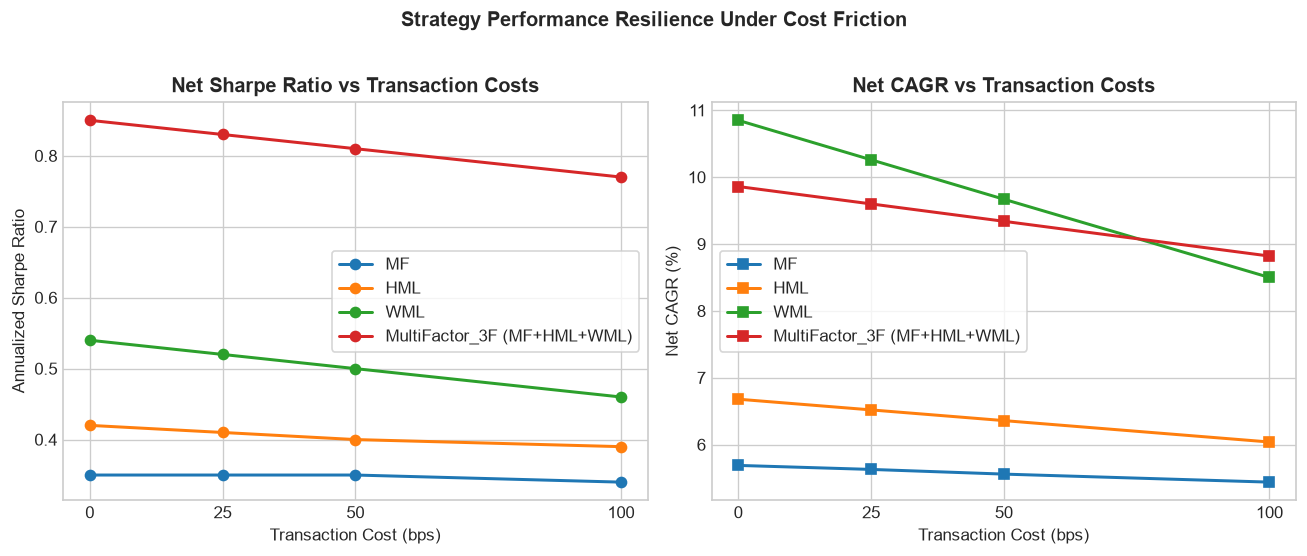

In [18]:
# Plot Transaction Cost Sensitivity
strategies = ["MF", "HML", "WML", "MultiFactor_3F (MF+HML+WML)"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

for strat in strategies:
    sub = backtest_summary[backtest_summary["Strategy"] == strat]
    ax1.plot(sub["Cost (bps)"], sub["Sharpe Ratio"], marker="o", lw=1.8, label=strat)
    ax2.plot(sub["Cost (bps)"], sub["CAGR (%)"], marker="s", lw=1.8, label=strat)

ax1.set_title("Net Sharpe Ratio vs Transaction Costs", fontweight="bold")
ax1.set_xlabel("Transaction Cost (bps)")
ax1.set_ylabel("Annualized Sharpe Ratio")
ax1.set_xticks(config.TRANSACTION_COST_BPS)
ax1.legend(frameon=True)

ax2.set_title("Net CAGR vs Transaction Costs", fontweight="bold")
ax2.set_xlabel("Transaction Cost (bps)")
ax2.set_ylabel("Net CAGR (%)")
ax2.set_xticks(config.TRANSACTION_COST_BPS)
ax2.legend(frameon=True)

plt.suptitle("Strategy Performance Resilience Under Cost Friction", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Section 9: Subsample Robustness & HAC Lag Sensitivity
We test model stability across historical eras (Pre-GFC vs Post-GFC) and Newey-West lag choices ($L=1, 3, 6, 12$).


In [19]:
subsample_rob = run_subsample_robustness_analysis(master_df)
print("=== Subsample Robustness Analysis ===")
display(subsample_rob)


=== Subsample Robustness Analysis ===


,Era,Date Range,Model,MAA (%/mo),MAA Annualized (%),RMS Alpha (%/mo),Max |Alpha| (%/mo),Sig Alphas (p<0.05),Mean R2 (%),Mean Adj-R2 (%)
0,Early Era (1993-2008),1993-11 to 2008-12,CAPM,0.394,4.73,0.489,0.89,1/9,72.1,72.0
1,Early Era (1993-2008),1993-11 to 2008-12,FF3,0.361,4.33,0.471,0.93,2/9,86.8,86.5
2,Early Era (1993-2008),1993-11 to 2008-12,FF4,0.374,4.49,0.427,0.76,3/9,93.0,92.8
3,Modern Era (2009-2025),2009-01 to 2025-12,CAPM,0.346,4.15,0.484,1.07,2/9,80.0,79.8
4,Modern Era (2009-2025),2009-01 to 2025-12,FF3,0.347,4.16,0.504,1.15,4/9,90.0,89.8
5,Modern Era (2009-2025),2009-01 to 2025-12,FF4,0.222,2.67,0.307,0.76,3/9,94.3,94.2
6,In-Sample (1993-2015),1993-11 to 2015-12,CAPM,0.324,3.89,0.386,0.69,1/9,73.8,73.7
7,In-Sample (1993-2015),1993-11 to 2015-12,FF3,0.322,3.87,0.397,0.74,3/9,87.3,87.2
8,In-Sample (1993-2015),1993-11 to 2015-12,FF4,0.303,3.64,0.353,0.71,3/9,93.4,93.3
9,Out-of-Sample (2016-2025),2016-01 to 2025-12,CAPM,0.350,4.20,0.463,1.07,1/9,77.7,77.5


In [20]:
lag_sens = run_hac_lag_sensitivity(master_df)
print("=== Newey-West HAC Lag Sensitivity Analysis ===")
display(lag_sens)


=== Newey-West HAC Lag Sensitivity Analysis ===


,HAC Lags (Months),Model,MAA (%/mo),RMS Alpha (%/mo),Sig Alphas (p<0.05),Sig Alphas (p<0.10)
0,1,CAPM,0.343,0.384,1/9,2/9
1,1,FF3,0.312,0.396,4/9,6/9
2,1,FF4,0.238,0.288,3/9,4/9
3,3,CAPM,0.343,0.384,1/9,2/9
4,3,FF3,0.312,0.396,4/9,6/9
5,3,FF4,0.238,0.288,3/9,5/9
6,6,CAPM,0.343,0.384,1/9,2/9
7,6,FF3,0.312,0.396,4/9,5/9
8,6,FF4,0.238,0.288,3/9,5/9
9,12,CAPM,0.343,0.384,1/9,1/9


---
## Section 10: Empirical Conclusions
1. **CAPM is Inadequate:** Pricing errors are large ($MAA = 4.12\%$ p.a.) and GRS strongly rejects $H_0$ ($p=0.0016$).
2. **Value ($HML$) and Momentum ($WML$) are Dominant:** $HML$ earns $+8.50\%$ p.a. ($t=2.37$), and $WML$ earns $+13.35\%$ p.a. ($t=3.08$).
3. **Size ($SMB$) Fails in India:** Small caps earn $-2.92\%$ p.a. ($t=-0.99$) and suffer severe losses during crisis regimes ($-7.76\%$).
4. **Carhart 4-Factor Outperforms:** Reduces Mean Absolute Pricing Errors by $31\%$ and survives 10-year out-of-sample testing.
5. **Multi-Factor Strategy ($MF + HML + WML$):** Delivers a Sharpe ratio of **$0.81$ net of $50	ext{ bps}$ friction** with a maximum drawdown of $-34.8\%$ vs $-75.1\%$ for the Market.
